## Discrete Delta Hedging

This notebook implements a discrete delta-hedging strategy for a European call option under the Black-Scholes framework.

Stock prices follow risk-neutral geometric Brownian motion, with hedge periodically rebalanced using Black-Scholes delta. Objective is to examine distribution of terminal hedging errors arising from discrete rebalancing. 

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [19]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

### Simulation Setup

Baseline simulation assumes correctly specified volatility, continuous interest accrual and zero transaction costs. Option is hedged using same volatility parameter used to generate stock prices. 

In [20]:
S0 = 100
sigma = 0.20
r = 0.05
T = 1
K = 100
n = 100
t_array = np.linspace(0, T, n+1)
rng = np.random.default_rng(4)

delta_t = T/n

### Hedging Methodology

A short call position is hedged by holding Δ shares of the underlying asset. Initial cash balance is

$$
B_0 = C_0 - \Delta_0 S_0
$$

At each rebalancing date, cash account is adjusted for changes in delta and accrues interest at the risk-free rate.

The terminal hedging error is

$$
\varepsilon_T = B_T + \Delta_{n-1}S_T - (S_T-K)^+
$$

where $B_T$ includes accumulated interest and all intermediate rebalancing cash flows.

Simulation uses vectorised NumPy operations and processes paths in batches to limit memory consumption.

In [21]:

M = 1000000
batch_size = 50000

errors = np.empty(M)

tau = T - t_array[:-1]
interest = np.exp(r * tau[1:])
drift = (r - 0.5 * sigma**2) * t_array

option_premium, _ = black_scholes_price(S0, K, T, r, sigma)

for start in range(0, M, batch_size):

    end = min(start + batch_size, M)
    batch_M = end - start

    randoms = rng.normal(0, np.sqrt(delta_t), size=(batch_M, n))
    zeros = np.zeros((batch_M, 1))

    brownian_increments = np.concatenate((zeros, randoms), axis=1)
    brownian = np.cumsum(brownian_increments, axis=1)

    diffusion = sigma * brownian
    price_factor = np.exp(drift + diffusion)
    prices = S0 * price_factor

    d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
    delta = norm.cdf(d1)

    delta_change = np.diff(delta, axis=1)

    total_cost = np.einsum(
        "ij,ij,j->i",
        delta_change,
        prices[:, 1:-1],
        interest
    )   
    
    initial_cash = option_premium - S0 * delta[:, 0]
    terminal_cash = initial_cash * np.exp(r * T) - total_cost

    
    portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]
    call_payoff = np.maximum(prices[:, -1] - K, 0)

    error = portfolio_value - call_payoff

    errors[start:end] = error

### Hedging Error Analysis

In [22]:

print("Mean:", np.mean(errors))
print("Standard deviation:", np.std(errors))
print("RMSE:", np.sqrt(np.mean(errors**2)))


Mean: -3.26210895211886e-05
Standard deviation: 0.6894484323682845
RMSE: 0.689448433140014


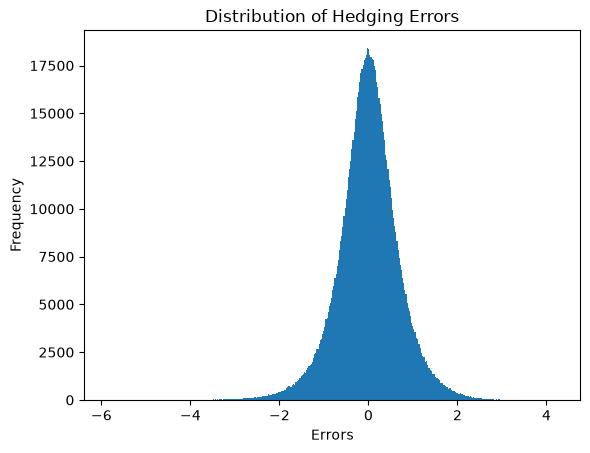

In [23]:
plt.hist(errors,
        bins = 400
         )

plt.xlabel("Errors")
plt.ylabel("Frequency")
plt.title("Distribution of Hedging Errors")

plt.show()

The mean terminal hedging error is approximately zero, consistent with the correctly specified Black–Scholes model.

However, individual paths produce non-zero errors because the hedge is rebalanced discretely rather than continuously. The resulting dispersion is reflected in the standard deviation and RMSE.

The following notebooks examine how rebalancing frequency, transaction costs and volatility misspecification affect these results.